# Gradient descent in a small neural network

Source: Stephen Welch (@stephencwelch), Neural Networks Demystified.

<h3 align = 'center'> Variables </h3>

|Code Symbol | Math Symbol | Definition | Dimensions
| :-: | :-: | :-: | :-: |
|X|$$X$$|Input Data, each row in an example| (numExamples, inputLayerSize)|
|y |$$y$$|target data|(numExamples, outputLayerSize)|
|W1 | $$W^{(1)}$$ | Layer 1 weights | (inputLayerSize, hiddenLayerSize) |
|W2 | $$W^{(2)}$$ | Layer 2 weights | (hiddenLayerSize, outputLayerSize) |
|z2 | $$z^{(2)}$$ | Layer 2 activation | (numExamples, hiddenLayerSize) |
|a2 | $$a^{(2)}$$ | Layer 2 activity | (numExamples, hiddenLayerSize) |
|z3 | $$z^{(3)}$$ | Layer 3 activation | (numExamples, outputLayerSize) |
|J | $$J$$ | Cost | (1, outputLayerSize) |

In [2]:
from partTwo import *

Populating the interactive namespace from numpy and matplotlib


In [3]:
NN = Neural_Network()

In [4]:
yHat = NN.forward(X)

In [5]:
yHat

array([[0.40488428],
       [0.47043329],
       [0.50153936]])

In [6]:
y

array([[0.75],
       [0.82],
       [0.93]])

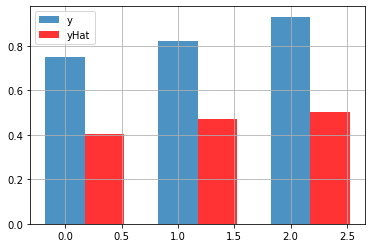

In [7]:
bar([0,1,2], y.flatten(), width = 0.35, alpha=0.8)
bar([0.35,1.35,2.35],yHat.flatten(), width = 0.35, color='r', alpha=0.8)
grid(1)
legend(['y', 'yHat'])

The squared prediction error gives the cost to be minimized.

The cost is half the sum of squared errors.

$$
J = \sum \frac{1}{2}(y-\hat{y})^2 \tag{5}
$$

With the inputs fixed, the cost depends on the network weights.

A small network can still have many possible weight combinations.

Testing a grid of candidate values illustrates the cost of exhaustive search.

In [8]:
import time

weightsToTry = np.linspace(-5,5,1000)
costs = np.zeros(1000)

startTime = time.process_time()
for i in range(1000):
    NN.W1[0,0] = weightsToTry[i]
    yHat = NN.forward(X)
    costs[i] = 0.5*sum((y-yHat)**2)

endTime = time.process_time()

In [9]:
timeElapsed = endTime-startTime
timeElapsed

0.015625

The minimum of the sampled cost gives the best weight on this grid.

Text(0.5, 0, 'Weight')

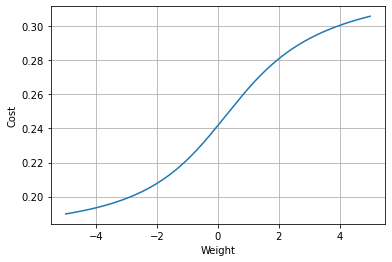

In [10]:
plot(weightsToTry, costs)
grid(1)
ylabel('Cost')
xlabel('Weight')

A grid search over two weights requires the product of the candidate counts.

In [11]:
weightsToTry = np.linspace(-5,5,1000)
costs = np.zeros((1000, 1000))

startTime = time.process_time()
for i in range(1000):
    for j in range(1000):
        NN.W1[0,0] = weightsToTry[i]
        NN.W1[0,1] = weightsToTry[j]
        yHat = NN.forward(X)
        costs[i, j] = 0.5*sum((y-yHat)**2)

endTime = time.process_time()

In [12]:
timeElapsed = endTime-startTime
timeElapsed

20.5625

The number of grid evaluations grows exponentially with the number of weights.

In [13]:
0.04*(1000**(9-1))/(3600*24*365)

1268391679350583.5

A derivative gives the direction in which a small weight change decreases the cost.

$$
z^{(2)} = XW^{(1)} \tag{1}\\
$$
$$
a^{(2)} = f(z^{(2)}) \tag{2}\\
$$
$$
z^{(3)} = a^{(2)}W^{(2)} \tag{3}\\
$$
$$
\hat{y} = f(z^{(3)}) \tag{4}\\
$$
$$
J = \sum \frac{1}{2}(y-\hat{y})^2 \tag{5}\\
$$

The layer equations define the cost as a function of the weights.

Partial derivatives give the sensitivity of the cost to each weight.

A positive derivative calls for a smaller weight; a negative derivative calls for a larger one.

Gradient descent takes repeated steps opposite to the gradient.

For a non-convex objective, gradient descent can settle at a local minimum.

Link to Yann's Talk:
http://videolectures.net/eml07_lecun_wia/

Batch gradient descent evaluates the gradient using all training samples.

## Sources

Source: [Stephen Welch, Neural Networks Demystified](https://github.com/stephencwelch/Neural-Networks-Demystified).

Source: [Codebasics](https://github.com/codebasics/deep-learning-keras-tf-tutorial).